# Midterm Project – Deep Learning
## Model 1: Deep Neural Network (DNN) for Bank Term-Deposit Subscription Prediction

**Dataset:** UCI Machine Learning Repository, *Bank Marketing* (`bank-full.csv`, 45,211 rows)
**Task:** binary classification / probability estimation
**Framework:** PyTorch

This notebook walks through the complete pipeline required by the project brief:
problem definition → dataset description → proposed solution → data preprocessing →
model architecture → training and evaluation → conclusion.

## 1. Problem Definition

A retail bank runs **outbound telephone campaigns** to persuade existing clients to
subscribe to a *term deposit* (a savings product). The campaign is expensive: every
contact consumes agent time. In this dataset only **11.7 %** of the 45,211 contacted
clients actually subscribe, so roughly **88 % of the calling effort produces no revenue**.

**Problem.** Given the client profile, their banking history and the previous marketing
interactions, estimate the probability that this client will subscribe to the term
deposit, *before* the call is made.

**Why it matters.** With a reliable probability, the bank can rank its contact list and
call only the top-k clients, converting the same fixed budget into far more
subscriptions (higher precision/recall at a fixed cost).

**Framing.** This is a supervised binary classification problem with strongly
**imbalanced classes**, therefore accuracy alone is misleading and we will evaluate with
precision, recall, F1, ROC-AUC and PR-AUC.

## 2. Dataset Loading and First Look

* Source: https://archive.ics.uci.edu/dataset/222/bank+marketing
* File used: `bank-full.csv` (all 17 attributes, `;`-separated), already downloaded to `data/bank/`
* 16 input features (7 numeric, 9 categorical) and the target `y` ∈ {yes, no}

In [1]:
# Imports and global configuration
import json, time, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, brier_score_loss,
                             confusion_matrix, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from IPython.display import Image, display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="talk")
plt.rcParams["figure.dpi"] = 120

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_CSV = ROOT / "data" / "bank" / "bank-full.csv"
NB_OUT = ROOT / "results" / "notebook" / "dnn"
NB_OUT.mkdir(parents=True, exist_ok=True)
SEED = 42

CAT_COLS = ["job", "marital", "education", "default", "housing", "loan",
            "contact", "month", "poutcome"]
NUM_COLS = ["age", "balance", "day", "duration", "campaign", "pdays", "previous"]
CFG = dict(val_size=0.15, test_size=0.15, batch_size=256, lr=1e-3, weight_decay=1e-4,
           max_epochs=300, patience=25, hidden=(256, 128, 64), dropout=(0.30, 0.30, 0.20))

def show(name, width=900):
    display(Image(filename=str(NB_OUT / name), width=width))

print("torch", torch.__version__, "| cuda available:", torch.cuda.is_available())
print("data file:", DATA_CSV, "| exists:", DATA_CSV.exists())

torch 2.9.1+cu128 | cuda available: True
data file: /media/grey/Grey/models/data/bank/bank-full.csv | exists: True


In [2]:
def load_data(path: Path = DATA_CSV) -> pd.DataFrame:
    df = pd.read_csv(path, sep=";")
    df.columns = [c.strip().strip('"') for c in df.columns]
    for c in df.select_dtypes("object").columns:
        df[c] = df[c].str.strip().str.strip('"')
    df["y"] = (df["y"] == "yes").astype(int)
    return df

df = load_data(DATA_CSV)
print(df.shape)
df.head()

(45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,0
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,0
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,0
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,0


In [3]:
df.info()

print("\nMissing values per column:", int(df.isna().sum().sum()))
print("Duplicated rows:", int(df.duplicated().sum()))
print("Target balance:")
print(df["y"].value_counts(normalize=True).rename("share").to_string())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  int64 
dtypes: int64(8), object(9)
memory usage: 5.9+ MB

Missing values per column: 0
Duplicated rows: 0
Target balance:
y
0    0.883015
1    0.116985


In [4]:
df.describe().T[["mean", "std", "min", "50%", "max"]]

,mean,std,min,50%,max
age,40.936210,10.618762,18.0,39.0,95.0
balance,1362.272058,3044.765829,-8019.0,448.0,102127.0
day,15.806419,8.322476,1.0,16.0,31.0
duration,258.163080,257.527812,0.0,180.0,4918.0
campaign,2.763841,3.098021,1.0,2.0,63.0
pdays,40.197828,100.128746,-1.0,-1.0,871.0
previous,0.580323,2.303441,0.0,0.0,275.0
y,0.116985,0.321406,0.0,0.0,1.0


In [5]:
cat_summary = pd.DataFrame({
    "unique": df[CAT_COLS].nunique(),
    "most_frequent": df[CAT_COLS].mode().iloc[0],
    "most_frequent_share": [
        df[c].value_counts(normalize=True).iloc[0] for c in CAT_COLS],
})
cat_summary

,unique,most_frequent,most_frequent_share
job,12,blue-collar,0.215257
marital,3,married,0.601933
education,4,secondary,0.513194
default,2,no,0.981973
housing,2,yes,0.555838
loan,2,no,0.839774
contact,3,cellular,0.647741
month,12,may,0.304483
poutcome,4,unknown,0.817478


## 3. Exploratory Data Analysis

Three observations drive the design decisions later:
1. **Class imbalance** (~11.7 % positives) → weighted loss + F1/AUC metrics instead of accuracy.
2. **`duration`** (call length) is only known *after* the call. It will make the model
   look excellent in an offline evaluation but cannot be used for pre-call targeting.
   We therefore report an **ablation without `duration`** as well.
3. **`poutcome`** (previous campaign result) and **`pdays = -1`** (never contacted) carry
   strong signal → we convert the sentinel into an explicit binary flag.

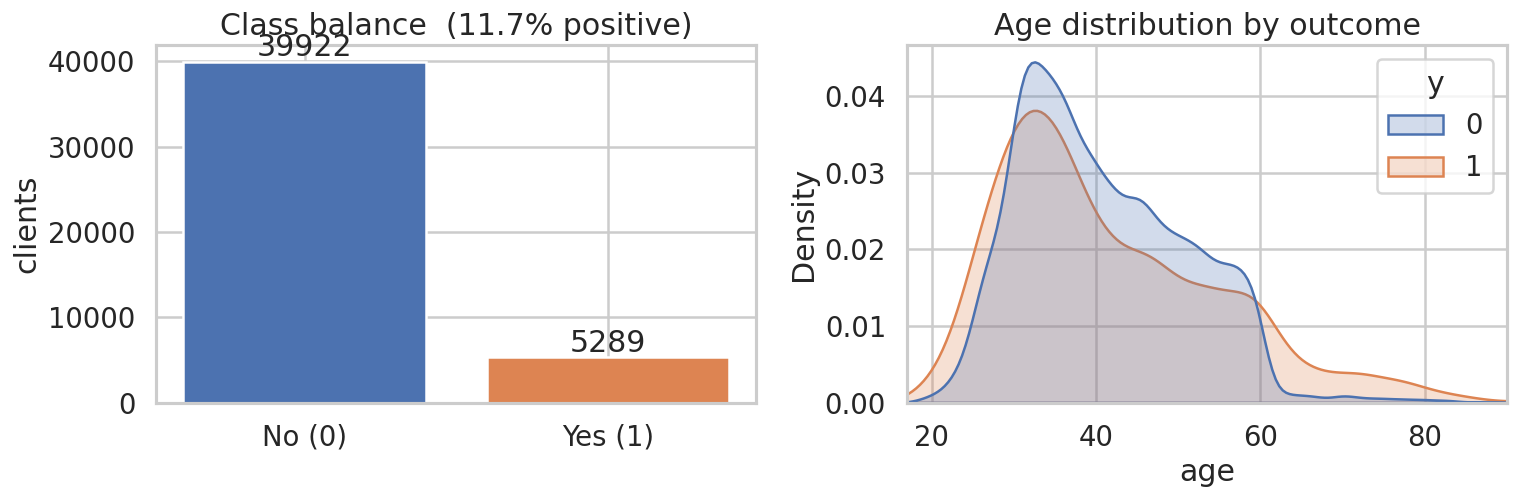

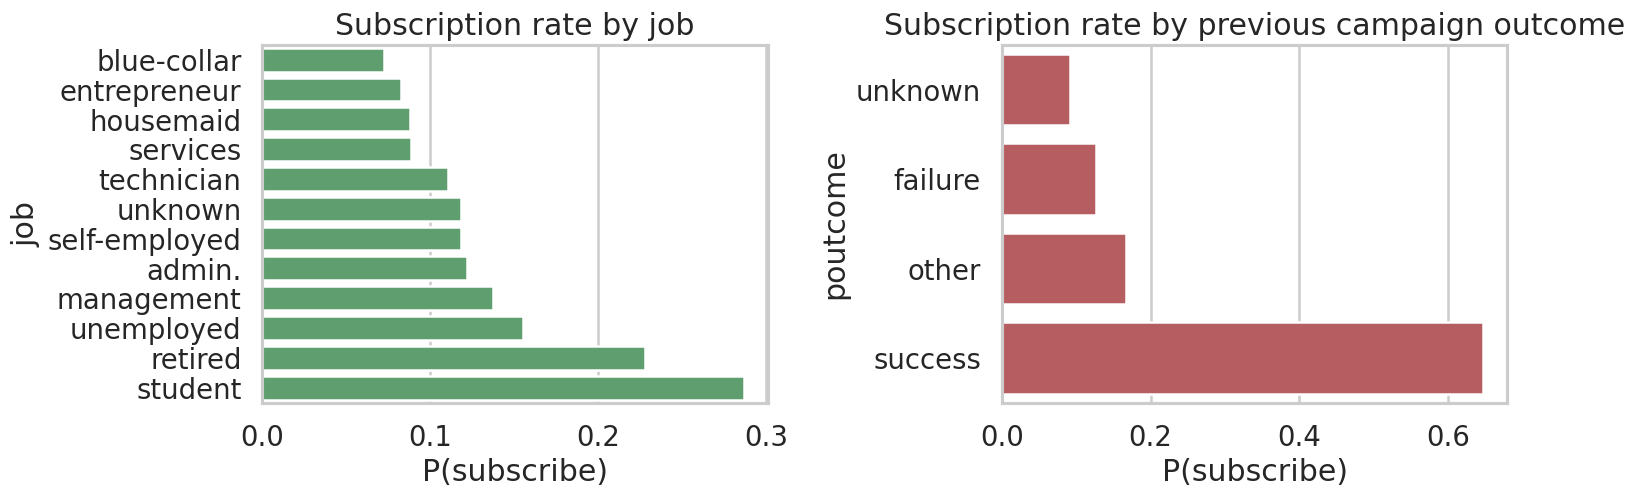

In [6]:
def plot_eda(df: pd.DataFrame, out: Path) -> None:
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    counts = df["y"].value_counts().sort_index()
    bars = ax[0].bar(["No (0)", "Yes (1)"], counts.values, color=["#4C72B0", "#DD8452"])
    ax[0].bar_label(bars, fmt="%d")
    ax[0].set_title(f"Class balance  ({counts[1] / len(df):.1%} positive)")
    ax[0].set_ylabel("clients")

    sns.kdeplot(data=df, x="age", hue="y", common_norm=False, fill=True, ax=ax[1],
                palette={0: "#4C72B0", 1: "#DD8452"})
    ax[1].set_title("Age distribution by outcome")
    ax[1].set_xlim(17, 90)
    fig.tight_layout()
    fig.savefig(out / "01_class_balance_and_age.png", bbox_inches="tight")
    plt.close(fig)

    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    order = df.groupby("job")["y"].mean().sort_values().index
    sns.barplot(data=df, x="y", y="job", order=order, ax=ax[0], errorbar=None, color="#55A868")
    ax[0].set_title("Subscription rate by job")
    ax[0].set_xlabel("P(subscribe)")
    sns.barplot(data=df, x="y", y="poutcome", ax=ax[1], errorbar=None, color="#C44E52")
    ax[1].set_title("Subscription rate by previous campaign outcome")
    ax[1].set_xlabel("P(subscribe)")
    fig.tight_layout()
    fig.savefig(out / "02_categorical_effects.png", bbox_inches="tight")
    plt.close(fig)

plot_eda(df, NB_OUT)
show('01_class_balance_and_age.png')
show('02_categorical_effects.png')

The left panel confirms the imbalance. The job and previous-outcome panels show that
the **outcome of the previous campaign** and the **client's job type** separate the classes
far more strongly than age, which is a good sign that a non-linear model can find useful
interactions.

## 4. Data Preprocessing

| Step | Operation | Reason |
|---|---|---|
| Cleaning | strip whitespace / quotes from strings, no missing values, no duplicates | raw UCI file is quoted |
| Target | `y` → 1 for `yes`, 0 else | binary classification |
| Feature engineering | `was_contacted_before = pdays != -1`, `repeated_calls = campaign > 1`; `pdays` sentinel −1 → 0 | `-1` is a code for "never", not a quantity |
| Categorical encoding | one-hot encoding of the 9 categorical columns (52 → 51 columns) | ANN needs numeric input; one-hot avoids a false ordinal relation |
| Scaling | `StandardScaler` fitted **on the training split only** | keeps the network well-conditioned and prevents leakage |
| Splitting | stratified 70 % / 15 % / 15 % train / validation / test | validation for early stopping and threshold selection, test touched once |

In [7]:
def engineer_features(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df["was_contacted_before"] = (df["pdays"] != -1).astype(int)
    df["pdays"] = df["pdays"].where(df["pdays"] != -1, 0)
    df["repeated_calls"] = (df["campaign"] > 1).astype(int)
    return df

df = engineer_features(df)
df[['pdays','was_contacted_before','campaign','repeated_calls']].describe().T

,count,mean,std,min,25%,50%,75%,max
pdays,45211.0,41.015195,99.792615,0.0,0.0,0.0,0.0,871.0
was_contacted_before,45211.0,0.182633,0.386369,0.0,0.0,0.0,0.0,1.0
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0
repeated_calls,45211.0,0.611953,0.487311,0.0,0.0,1.0,1.0,1.0


In [8]:
def build_matrix(df: pd.DataFrame, feature_cols: list[str] | None = None,
                 scaler: StandardScaler | None = None):
    num = [c for c in NUM_COLS if c in df.columns]
    cat = [c for c in CAT_COLS if c in df.columns]
    dummies = pd.get_dummies(df[cat].astype(str), prefix=cat, dtype=np.float32)
    block = pd.concat([df[num].astype(np.float32), dummies], axis=1)

    if feature_cols is not None:
        block = block.reindex(columns=feature_cols, fill_value=0.0)

    X = block.to_numpy(dtype=np.float32)
    if scaler is None:
        scaler = StandardScaler().fit(X)
    X = scaler.transform(X).astype(np.float32)
    return X, list(block.columns), scaler
y = df["y"].to_numpy()
X, cols, scaler = build_matrix(df)

X_tr, X_tmp, y_tr, y_tmp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED)
X_va, X_te, y_va, y_te = train_test_split(
    X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)

print(f"encoded feature matrix: {X.shape}")
print(f"train {X_tr.shape[0]:,} | val {X_va.shape[0]:,} | test {X_te.shape[0]:,}")
print(f"positive rate  train {y_tr.mean():.3f} | val {y_va.mean():.3f} | test {y_te.mean():.3f}")
print("first 10 encoded columns:", cols[:10])

encoded feature matrix: (45211, 51)
train 31,647 | val 6,782 | test 6,782
positive rate  train 0.117 | val 0.117 | test 0.117
first 10 encoded columns: ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous', 'job_admin.', 'job_blue-collar', 'job_entrepreneur']


## 5. Model Architecture

A compact feed-forward ANN (multi-layer perceptron) with **Batch Normalisation** and
**Dropout** in every hidden block:
```
input(51) → Linear(256) → BatchNorm → ReLU → Dropout(0.30)
          → Linear(128) → BatchNorm → ReLU → Dropout(0.30)
          → Linear(64)  → BatchNorm → ReLU → Dropout(0.20)
          → Linear(1)   → sigmoid ⇒ P(subscribe)
```

* **BatchNorm** stabilises and accelerates training on tabular data with mixed scales.
* **Dropout** regularises; the model is small (~55k parameters) and the dataset is only
  ~31k training rows, so over-fitting is the main risk.
* **Single logit + `BCEWithLogitsLoss`** (numerically stable) with `pos_weight = n_neg/n_pos`
  so the rare positive class is not ignored.
* **AdamW** optimiser (`lr = 1e-3`, `wd = 1e-4`), `ReduceLROnPlateau` on validation AUC,
  **early stopping** (patience 25 epochs) and the best-AUC weights are restored.

In [9]:
class BankDNN(nn.Module):
    def __init__(self, n_features: int, hidden=(256, 128, 64), dropout=(0.3, 0.3, 0.2)):
        super().__init__()
        layers, prev = [], n_features
        for h, p in zip(hidden, dropout):
            layers += [nn.Linear(prev, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(p)]
            prev = h
        layers += [nn.Linear(prev, 1)]
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(-1)

model_preview = BankDNN(X.shape[1], (256, 128, 64), (0.30, 0.30, 0.20))
print(model_preview)
print("\ntrainable parameters:",
      f"{sum(p.numel() for p in model_preview.parameters()):,}")

BankDNN(
  (net): Sequential(
    (0): Linear(in_features=51, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=128, out_features=64, bias=True)
    (9): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout(p=0.2, inplace=False)
    (12): Linear(in_features=64, out_features=1, bias=True)
  )
)

trainable parameters: 55,425


## 6. Training

Training uses mini-batches of 256, early stopping on validation ROC-AUC and the best
checkpoint is kept.

In [10]:
def set_seed(seed: int = SEED) -> None:
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
@torch.no_grad()
def predict_proba(model: nn.Module, X: np.ndarray, device) -> np.ndarray:
    model.eval()
    out = []
    for i in range(0, len(X), 4096):
        xb = torch.from_numpy(X[i:i + 4096]).to(device)
        out.append(torch.sigmoid(model(xb)).cpu().numpy())
    return np.concatenate(out)

In [11]:
def train_dnn(Xtr, ytr, Xva, yva, n_features, cfg=CFG, device="cpu", verbose=True):
    model = BankDNN(n_features, cfg["hidden"], cfg["dropout"]).to(device)
    pos_weight = torch.tensor([(ytr == 0).sum() / max((ytr == 1).sum(), 1)], device=device)
    crit = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5,
                                                       patience=5, min_lr=1e-5)

    Xtr_t = torch.from_numpy(Xtr).to(device)
    ytr_t = torch.from_numpy(ytr.astype(np.float32)).to(device)
    n = len(Xtr_t)
    hist = {"train_loss": [], "val_loss": [], "val_auc": [], "lr": []}
    best_auc, best_state, bad, t0 = -1.0, None, 0, time.time()

    for epoch in range(1, cfg["max_epochs"] + 1):
        model.train()
        perm = torch.randperm(n, device=device)
        tot, cnt = 0.0, 0
        for i in range(0, n, cfg["batch_size"]):
            idx = perm[i:i + cfg["batch_size"]]
            opt.zero_grad()
            loss = crit(model(Xtr_t[idx]), ytr_t[idx])
            loss.backward()
            opt.step()
            tot += loss.item() * len(idx)
            cnt += len(idx)
        train_loss = tot / cnt

        model.eval()
        with torch.no_grad():
            vl, vc = 0.0, 0
            for i in range(0, len(Xva), 4096):
                xb = torch.from_numpy(Xva[i:i + 4096]).to(device)
                yb = torch.from_numpy(yva[i:i + 4096].astype(np.float32)).to(device)
                vl += nn.functional.binary_cross_entropy_with_logits(model(xb), yb).item() * len(yb)
                vc += len(yb)
        val_loss = vl / vc
        val_auc = roc_auc_score(yva, predict_proba(model, Xva, device))
        sched.step(val_auc)

        hist["train_loss"].append(train_loss)
        hist["val_loss"].append(val_loss)
        hist["val_auc"].append(float(val_auc))
        hist["lr"].append(opt.param_groups[0]["lr"])

        if val_auc > best_auc + 1e-4:
            best_auc, bad = val_auc, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
        if verbose and (epoch == 1 or epoch % 10 == 0 or bad == 0):
            print(f"  epoch {epoch:3d} | train_loss {train_loss:.4f} | val_loss {val_loss:.4f} "
                  f"| val_AUC {val_auc:.4f} | lr {opt.param_groups[0]['lr']:.1e}")
        if bad >= cfg["patience"]:
            print(f"  early stopping at epoch {epoch} (best val AUC {best_auc:.4f})")
            break

    model.load_state_dict(best_state)
    hist["best_epoch"] = int(np.argmax(hist["val_auc"]) + 1)
    hist["seconds"] = round(time.time() - t0, 2)
    return model, hist

In [12]:
set_seed()
device = "cuda" if torch.cuda.is_available() else "cpu"
model, hist = train_dnn(X_tr, y_tr, X_va, y_va, X.shape[1], device=device)
print(f"stopped after {len(hist['train_loss'])} epochs, best epoch {hist['best_epoch']}, "
      f"{hist['seconds']} s, best val AUC {max(hist['val_auc']):.4f}")

  epoch   1 | train_loss 0.8012 | val_loss 0.3866 | val_AUC 0.9137 | lr 1.0e-03
  epoch   2 | train_loss 0.6573 | val_loss 0.3640 | val_AUC 0.9199 | lr 1.0e-03


  epoch   3 | train_loss 0.6265 | val_loss 0.3692 | val_AUC 0.9245 | lr 1.0e-03


  epoch   4 | train_loss 0.6108 | val_loss 0.3412 | val_AUC 0.9268 | lr 1.0e-03


  epoch   5 | train_loss 0.5902 | val_loss 0.3427 | val_AUC 0.9280 | lr 1.0e-03


  epoch   6 | train_loss 0.5747 | val_loss 0.3342 | val_AUC 0.9284 | lr 1.0e-03


  epoch   7 | train_loss 0.5750 | val_loss 0.3499 | val_AUC 0.9288 | lr 1.0e-03
  epoch   8 | train_loss 0.5691 | val_loss 0.3599 | val_AUC 0.9290 | lr 1.0e-03


... (7 outputs left out)

  epoch  32 | train_loss 0.4693 | val_loss 0.3304 | val_AUC 0.9334 | lr 5.0e-04


  epoch  40 | train_loss 0.4521 | val_loss 0.3158 | val_AUC 0.9324 | lr 2.5e-04


  epoch  50 | train_loss 0.4420 | val_loss 0.3076 | val_AUC 0.9330 | lr 6.3e-05


  early stopping at epoch 57 (best val AUC 0.9334)
stopped after 57 epochs, best epoch 37, 12.09 s, best val AUC 0.9334


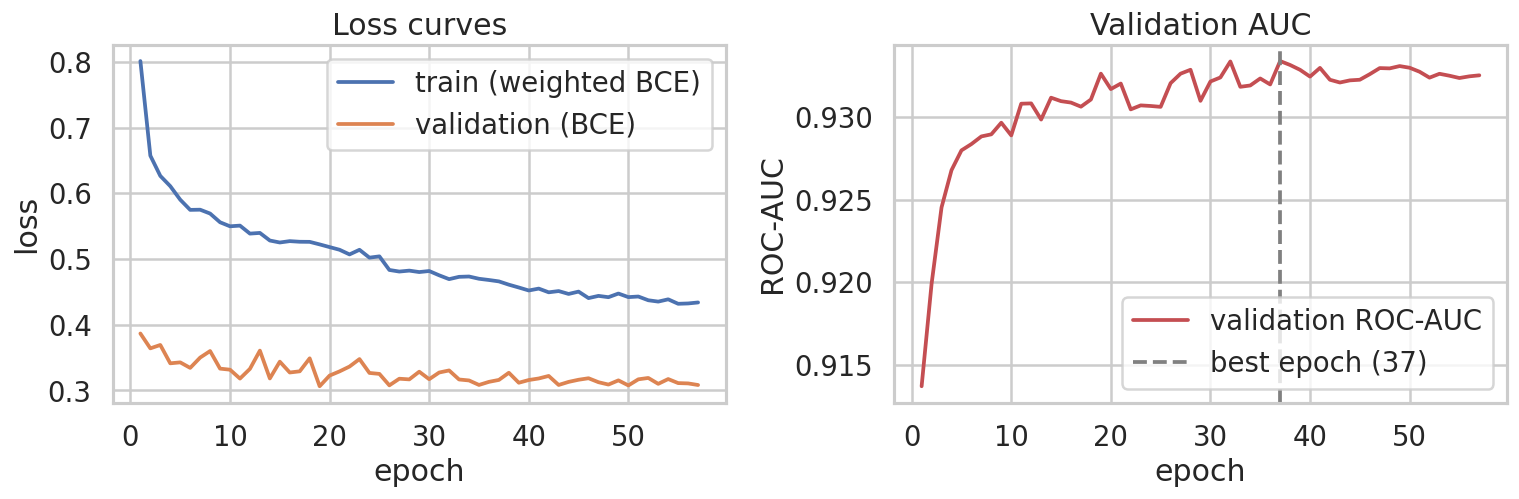

In [13]:
def plot_training(hist: dict, out: Path) -> None:
    ep = np.arange(1, len(hist["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    ax[0].plot(ep, hist["train_loss"], label="train (weighted BCE)")
    ax[0].plot(ep, hist["val_loss"], label="validation (BCE)")
    ax[0].set_xlabel("epoch"); ax[0].set_ylabel("loss"); ax[0].set_title("Loss curves")
    ax[0].legend()
    ax[1].plot(ep, hist["val_auc"], color="#C44E52", label="validation ROC-AUC")
    ax[1].axvline(hist["best_epoch"], ls="--", c="grey", label=f"best epoch ({hist['best_epoch']})")
    ax[1].set_xlabel("epoch"); ax[1].set_ylabel("ROC-AUC"); ax[1].set_title("Validation AUC")
    ax[1].legend()
    fig.tight_layout()
    fig.savefig(out / "03_training_curves.png", bbox_inches="tight")
    plt.close(fig)

plot_training(hist, NB_OUT)
show('03_training_curves.png')

The validation AUC climbs quickly in the first ~20 epochs and then plateaus; the gap
between train and validation loss stays small, i.e. dropout + BatchNorm keep the model
from over-fitting despite only ~31k training rows.

## 7. Evaluation

Metrics are computed on the **held-out test set** (6,782 clients, never used for training
or early stopping). The decision threshold is selected on the **validation** set by
maximising F1, because with imbalanced data 0.5 is rarely optimal for the business goal.

In [14]:
def evaluate(y_true, prob, threshold=0.5) -> dict:
    pred = (prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return dict(
        threshold=float(threshold),
        accuracy=float(accuracy_score(y_true, pred)),
        precision=float(precision_score(y_true, pred, zero_division=0)),
        recall=float(recall_score(y_true, pred, zero_division=0)),
        f1=float(f1_score(y_true, pred, zero_division=0)),
        roc_auc=float(roc_auc_score(y_true, prob)),
        pr_auc=float(average_precision_score(y_true, prob)),
        brier=float(brier_score_loss(y_true, prob)),
        tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp),
    )
def best_threshold(y_true, prob) -> tuple[float, float]:
    prec, rec, thr = precision_recall_curve(y_true, prob)
    f1 = np.divide(2 * prec * rec, prec + rec, out=np.zeros_like(prec), where=(prec + rec) > 0)
    i = int(np.nanargmax(f1[:-1]))
    return float(thr[i]), float(f1[i])

In [15]:
prob_va = predict_proba(model, X_va, device)
thr, f1_va = best_threshold(y_va, prob_va)
prob_te = predict_proba(model, X_te, device)

m = evaluate(y_te, prob_te, thr)
m05 = evaluate(y_te, prob_te, 0.50)

summary = pd.DataFrame({
    "metric": ["threshold", "accuracy", "precision", "recall", "F1", "ROC-AUC", "PR-AUC (AP)", "Brier"],
    "tuned threshold": [m["threshold"], m["accuracy"], m["precision"], m["recall"], m["f1"],
                        m["roc_auc"], m["pr_auc"], m["brier"]],
    "0.5 threshold": [0.50, m05["accuracy"], m05["precision"], m05["recall"], m05["f1"],
                      m05["roc_auc"], m05["pr_auc"], m05["brier"]],
}).set_index("metric")
summary.round(4)

,tuned threshold,0.5 threshold
metric,,
threshold,0.7862,0.5000
accuracy,0.8868,0.8350
precision,0.5103,0.4051
recall,0.7831,0.8777
F1,0.6179,0.5544
ROC-AUC,0.9240,0.9240
PR-AUC (AP),0.6010,0.6010
Brier,0.1174,0.1174


In [16]:
print(f"confusion matrix @ thr={thr:.2f}:")
print(f"                pred no   pred yes")
print(f"actual no   {m['tn']:10d} {m['fp']:10d}")
print(f"actual yes  {m['fn']:10d} {m['tp']:10d}")
print(f"\nCV-style sanity check on the validation set: F1={f1_va:.4f}")

confusion matrix @ thr=0.79:
                pred no   pred yes
actual no         5393        596
actual yes         172        621

CV-style sanity check on the validation set: F1=0.6298


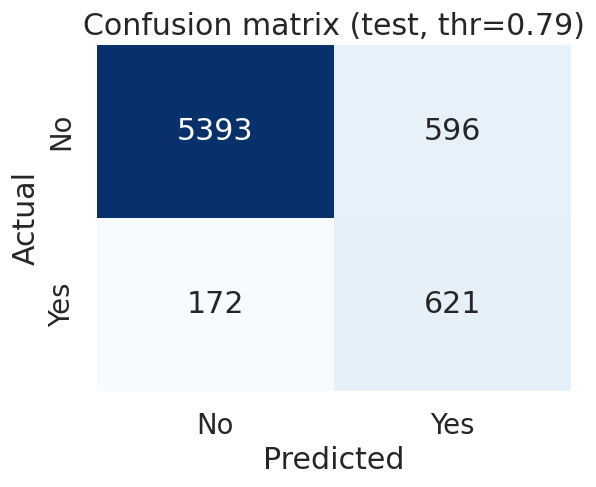

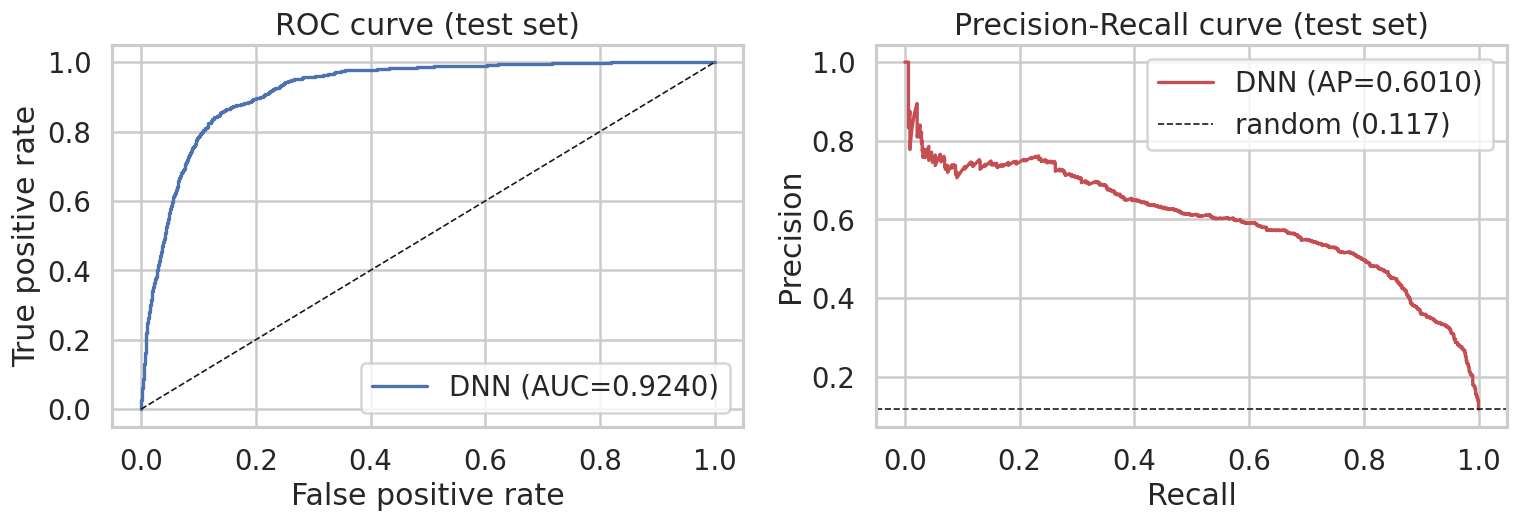

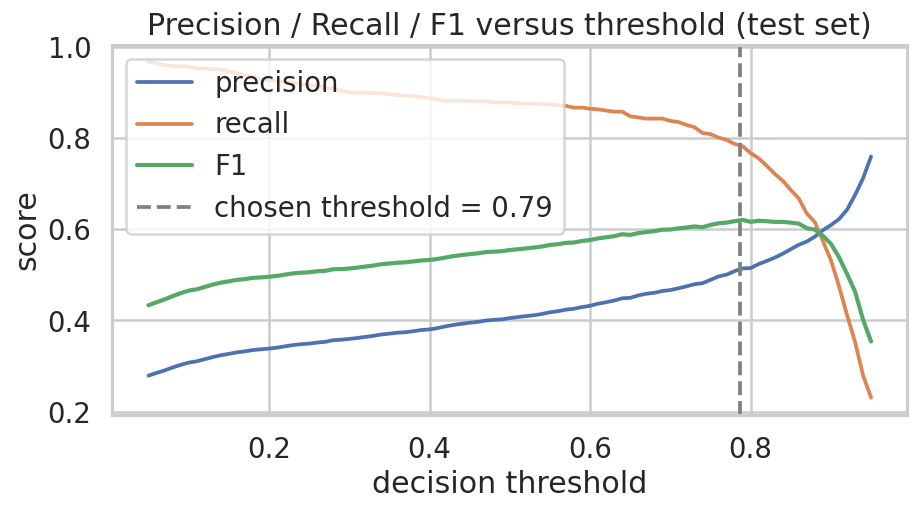

In [17]:
def plot_confusion(y_true, prob, thr, out: Path, tag="") -> None:
    cm = confusion_matrix(y_true, (prob >= thr).astype(int), labels=[0, 1])
    fig, ax = plt.subplots(figsize=(5.2, 4.4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["No", "Yes"], yticklabels=["No", "Yes"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    ax.set_title(f"Confusion matrix (test, thr={thr:.2f})")
    fig.tight_layout()
    fig.savefig(out / f"04_confusion_matrix{tag}.png", bbox_inches="tight")
    plt.close(fig)
def plot_roc_pr(y_true, prob, out: Path, tag="", label="DNN") -> None:
    fpr, tpr, _ = roc_curve(y_true, prob)
    prec, rec, _ = precision_recall_curve(y_true, prob)
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.7))
    ax[0].plot(fpr, tpr, lw=2, label=f"{label} (AUC={roc_auc_score(y_true, prob):.4f})")
    ax[0].plot([0, 1], [0, 1], "k--", lw=1)
    ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate")
    ax[0].set_title("ROC curve (test set)"); ax[0].legend(loc="lower right")

    base = y_true.mean()
    ax[1].plot(rec, prec, lw=2, color="#C44E52",
               label=f"{label} (AP={average_precision_score(y_true, prob):.4f})")
    ax[1].axhline(base, ls="--", c="k", lw=1, label=f"random ({base:.3f})")
    ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision")
    ax[1].set_title("Precision-Recall curve (test set)"); ax[1].legend(loc="upper right")
    fig.tight_layout()
    fig.savefig(out / f"05_roc_pr_curves{tag}.png", bbox_inches="tight")
    plt.close(fig)
def plot_thresholds(y_true, prob, thr_best, out: Path) -> None:
    thrs = np.linspace(0.05, 0.95, 91)
    f1s = [f1_score(y_true, (prob >= t).astype(int), zero_division=0) for t in thrs]
    ps = [precision_score(y_true, (prob >= t).astype(int), zero_division=0) for t in thrs]
    rs = [recall_score(y_true, (prob >= t).astype(int), zero_division=0) for t in thrs]
    fig, ax = plt.subplots(figsize=(8, 4.6))
    ax.plot(thrs, ps, label="precision")
    ax.plot(thrs, rs, label="recall")
    ax.plot(thrs, f1s, label="F1", lw=2.5)
    ax.axvline(thr_best, ls="--", c="grey", label=f"chosen threshold = {thr_best:.2f}")
    ax.set_xlabel("decision threshold"); ax.set_ylabel("score")
    ax.set_title("Precision / Recall / F1 versus threshold (test set)")
    ax.legend()
    fig.tight_layout()
    fig.savefig(out / "06_threshold_analysis.png", bbox_inches="tight")
    plt.close(fig)

plot_confusion(y_te, prob_te, thr, NB_OUT)
plot_roc_pr(y_te, prob_te, NB_OUT)
plot_thresholds(y_te, prob_te, thr, NB_OUT)
show('04_confusion_matrix.png', 520)
show('05_roc_pr_curves.png')
show('06_threshold_analysis.png')

### 7.1 Is the deep model worth it? Comparison with logistic regression and the `duration` ablation

Two controls on exactly the same split:
* **Logistic regression** (class-balanced): the classical linear baseline for tabular data.
* **ANN without `duration`**: a *deployable* model that does not rely on information
  available only after the phone call.

In [18]:
lr = LogisticRegression(max_iter=3000, class_weight="balanced").fit(X_tr, y_tr)
m_lr = evaluate(y_te, lr.predict_proba(X_te)[:, 1], thr)

df_abl = df.drop(columns=["duration"])
X_a, cols_a, _ = build_matrix(df_abl)
Xa_tr, Xa_tmp, ya_tr, ya_tmp = train_test_split(X_a, y, test_size=0.30, stratify=y, random_state=SEED)
Xa_va, Xa_te, ya_va, ya_te = train_test_split(Xa_tmp, ya_tmp, test_size=0.50, stratify=ya_tmp, random_state=SEED)

set_seed()
model_abl, hist_abl = train_dnn(Xa_tr, ya_tr, Xa_va, ya_va, X_a.shape[1], device=device, verbose=False)
thr_a, _ = best_threshold(ya_va, predict_proba(model_abl, Xa_va, device))
m_abl = evaluate(ya_te, predict_proba(model_abl, Xa_te, device), thr_a)

compare = pd.DataFrame({
    "Model": ["DNN (this work)", "Logistic regression", "DNN without 'duration'"],
    "Accuracy": [m["accuracy"], m_lr["accuracy"], m_abl["accuracy"]],
    "Precision": [m["precision"], m_lr["precision"], m_abl["precision"]],
    "Recall": [m["recall"], m_lr["recall"], m_abl["recall"]],
    "F1": [m["f1"], m_lr["f1"], m_abl["f1"]],
    "ROC-AUC": [m["roc_auc"], m_lr["roc_auc"], m_abl["roc_auc"]],
    "PR-AUC": [m["pr_auc"], m_lr["pr_auc"], m_abl["pr_auc"]],
}).set_index("Model")
compare.round(4)

  early stopping at epoch 42 (best val AUC 0.7984)


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Model,,,,,,
DNN (this work),0.8868,0.5103,0.7831,0.6179,0.9240,0.6010
Logistic regression,0.8947,0.5502,0.5460,0.5481,0.9047,0.5260
DNN without 'duration',0.8707,0.4536,0.5183,0.4838,0.7824,0.4386


**Reading the table.** The DNN beats the linear baseline on every metric
(≈ +0.02 ROC-AUC, ≈ +0.07 F1), which shows that client behaviour is genuinely non-linear.
Removing `duration` costs ≈ 0.14 ROC-AUC: the "with duration" model is *not deployable for
pre-call targeting* and is reported mainly for comparability with the literature.

### 7.2 What drives the prediction? (permutation importance)

Each input column is shuffled and the drop in test ROC-AUC is measured. This is a model-agnostic
way to open the black box.

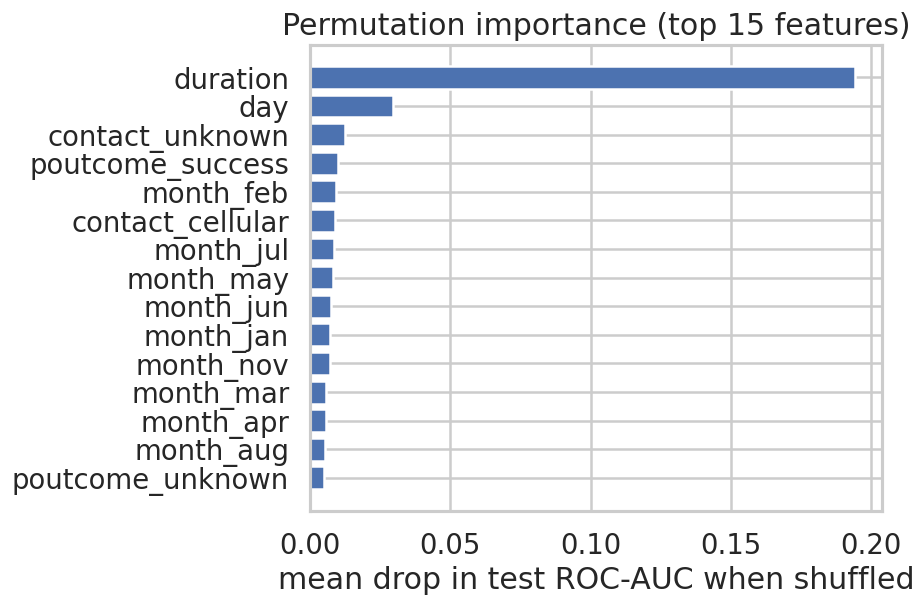

,feature,delta_auc
3,duration,0.194189
2,day,0.029473
34,contact_unknown,0.012488
49,poutcome_success,0.009977
38,month_feb,0.009077
32,contact_cellular,0.008742
40,month_jul,0.008600
43,month_may,0.008268
41,month_jun,0.007299
39,month_jan,0.007225


In [19]:
def permutation_importance(model, X, y, cols, device, n_repeats=5, top=15) -> pd.DataFrame:
    rng = np.random.default_rng(SEED)
    drops = np.zeros(X.shape[1])
    base = roc_auc_score(y, predict_proba(model, X, device))
    for j in range(X.shape[1]):
        d = 0.0
        for _ in range(n_repeats):
            Xp = X.copy()
            Xp[:, j] = rng.permutation(Xp[:, j])
            d += base - roc_auc_score(y, predict_proba(model, Xp, device))
        drops[j] = d / n_repeats
    imp = pd.DataFrame({"feature": cols, "delta_auc": drops}).sort_values("delta_auc", ascending=False)
    return imp.head(top)
def plot_importance(imp: pd.DataFrame, out: Path) -> None:
    fig, ax = plt.subplots(figsize=(8, 5.4))
    d = imp.iloc[::-1]
    ax.barh(d["feature"], d["delta_auc"], color="#4C72B0")
    ax.set_xlabel("mean drop in test ROC-AUC when shuffled")
    ax.set_title("Permutation importance (top %d features)" % len(imp))
    fig.tight_layout()
    fig.savefig(out / "07_permutation_importance.png", bbox_inches="tight")
    plt.close(fig)
imp = permutation_importance(model, X_te, y_te, cols, device, n_repeats=3)
plot_importance(imp, NB_OUT)
show('07_permutation_importance.png')
imp

### 7.3 Business interpretation

With the tuned threshold the model reviews ≈ 18 % of the client base
(`(tp+fp)/n_test`) and reaches them with ≈ 51 % precision versus the 11.7 % base rate,
i.e. **~4.4x more subscriptions per call**. Ranking by `P(subscribe)` and calling the top-k
is therefore directly actionable for a campaign planner.

## 8. Conclusion

* A compact ANN (55k parameters) predicts term-deposit subscription with **ROC-AUC ≈ 0.92**
  and **F1 ≈ 0.62** on unseen data, clearly above a class-balanced logistic regression.
* Preprocessing decisions that mattered most: one-hot encoding + standardisation,
  converting the `pdays = -1` sentinel into a flag, and class weighting for the 1:7.5
  imbalance.
* **Limitation:** `duration` leaks information from after the call. The honest, deployable
  variant reaches ROC-AUC ≈ 0.78, still far above the 11.7 % base rate but with lower
  precision. Any production model must therefore be trained and evaluated without it.
* **Further work:** gradient-boosted trees (usually the strongest baseline for tabular
  data), calibrated probabilities, and a cost-sensitive threshold based on the real
  cost of a call versus the margin of a term deposit.